# VigiaIA ? An?lise experimental

**Disciplina:** Generative AI for Engineering  
**Tema:** Mobilidade Urbana  
**Objetivo:** analisar a recupera??o documental e comparar tr?s configura??es: Base, RAG e Agent + RAG.

Este notebook analisa um resultado real previamente registrado. Ele n?o executa novamente o LLM nem altera os arquivos originais.


## 1. Prepara??o

O arquivo JSON de evid?ncias foi inclu?do em `docs/evidencias/` para permitir a reprodu??o desta an?lise.


In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RESULT_PATH = Path("../docs/evidencias/avaliacao-20261110-152046.json")
with RESULT_PATH.open(encoding="utf-8") as f:
    evaluation = json.load(f)

print("Arquivo carregado:", RESULT_PATH)
print("Execu??es registradas:", len(evaluation["runs"]))


Arquivo carregado: ..\docs\evidencias\avaliacao-20261110-152046.json
Execu??es registradas: 36


## 2. M?tricas de recupera??o

Recall@1 verifica se a fonte esperada aparece em primeiro lugar. Recall@3 verifica se aparece entre as tr?s primeiras. O caso sem fonte esperada (QA010) ? exclu?do do c?lculo.


In [2]:
retrieval = evaluation["retrieval"]

retrieval_summary = pd.DataFrame([{
    "Casos eleg?veis": retrieval["eligible_cases"],
    "Casos exclu?dos": retrieval["excluded_abstention_cases"],
    "Recall@1": retrieval["recall_at_1"],
    "Recall@3": retrieval["recall_at_3"],
}])

display(retrieval_summary)


,Casos eleg?veis,Casos exclu?dos,Recall@1,Recall@3
0,11,1,1.0,1.0


In [3]:
retrieval_details = pd.DataFrame(retrieval["details"])
display(retrieval_details[["id", "expected_sources", "top3_sources", "hit_at_1", "hit_at_3"]])


,id,expected_sources,top3_sources,hit_at_1,hit_at_3
0,QA001,[VIGIAVIA_MVP_SINTESE],"[VIGIAVIA_MVP_SINTESE, VIGIAVIA_RPA_SINTESE, V...",True,True
1,QA002,[VIGIAVIA_MVP_SINTESE],"[VIGIAVIA_MVP_SINTESE, VIGIAVIA_MVP_SINTESE, V...",True,True
2,QA003,[VIGIAVIA_MVP_SINTESE],"[VIGIAVIA_MVP_SINTESE, VIGIAVIA_MVP_SINTESE, V...",True,True
3,QA004,[VIGIAVIA_MVP_SINTESE],"[VIGIAVIA_MVP_SINTESE, VIGIAVIA_MVP_SINTESE, V...",True,True
4,QA005,[VIGIAVIA_MVP_SINTESE],"[VIGIAVIA_MVP_SINTESE, VIGIAVIA_MVP_SINTESE, V...",True,True
5,QA006,[VIGIAVIA_RPA_SINTESE],"[VIGIAVIA_RPA_SINTESE, VIGIAVIA_RPA_SINTESE, V...",True,True
6,QA007,[VIGIAVIA_RPA_SINTESE],"[VIGIAVIA_RPA_SINTESE, VIGIAVIA_RPA_SINTESE, V...",True,True
7,QA008,[VIGIAVIA_RPA_SINTESE],"[VIGIAVIA_RPA_SINTESE, VIGIAVIA_RPA_SINTESE, V...",True,True
8,QA009,[VIGIAVIA_MVP_SINTESE],"[VIGIAVIA_MVP_SINTESE, VIGIAVIA_RPA_SINTESE, V...",True,True
9,QA010,[],"[VIGIAVIA_MVP_SINTESE, VIGIAVIA_MVP_SINTESE, V...",None,None


## 3. Compara??o das configura??es

`schema_valid_rate` representa a taxa de respostas que passaram pela valida??o estrutural implementada. `coverage_rate` representa a propor??o de casos com cita??es. `reference_valid_rate` representa a validade das refer?ncias entre os casos citados. S?o m?tricas diferentes.


In [4]:
metrics = evaluation["response_metrics"]

rows = []
for mode, result in metrics.items():
    citations = result["citation_metrics"]
    latency = result["latency"]
    rows.append({
        "Configura??o": mode,
        "Casos": result["total_cases"],
        "Execu??es bem-sucedidas": result["successful_cases"],
        "Erros de execu??o": result["execution_errors"],
        "JSON/estrutura v?lida": result["schema_valid_rate"],
        "Cobertura de cita??es": citations["coverage_rate"],
        "Validade das refer?ncias": citations["reference_valid_rate"],
        "Recusas corretas": result["correct_abstention_rate"],
        "Completude dos termos": result["expected_terms_complete_rate"],
        "Lat?ncia m?dia (s)": latency["average_seconds"],
        "Lat?ncia mediana (s)": latency["median_seconds"],
    })

comparison = pd.DataFrame(rows)
display(comparison)


,Configura??o,Casos,Execu??es bem-sucedidas,Erros de execu??o,JSON/estrutura v?lida,Cobertura de cita??es,Validade das refer?ncias,Recusas corretas,Completude dos termos,Lat?ncia m?dia (s),Lat?ncia mediana (s)
0,base,12,10,2,1.0,NaN,NaN,1.0,0.000000,32.603,2.445
1,rag,12,12,0,1.0,0.916667,1.0,1.0,0.363636,2.492,2.684
2,agent_rag,12,12,0,1.0,0.916667,1.0,1.0,1.000000,0.225,0.002


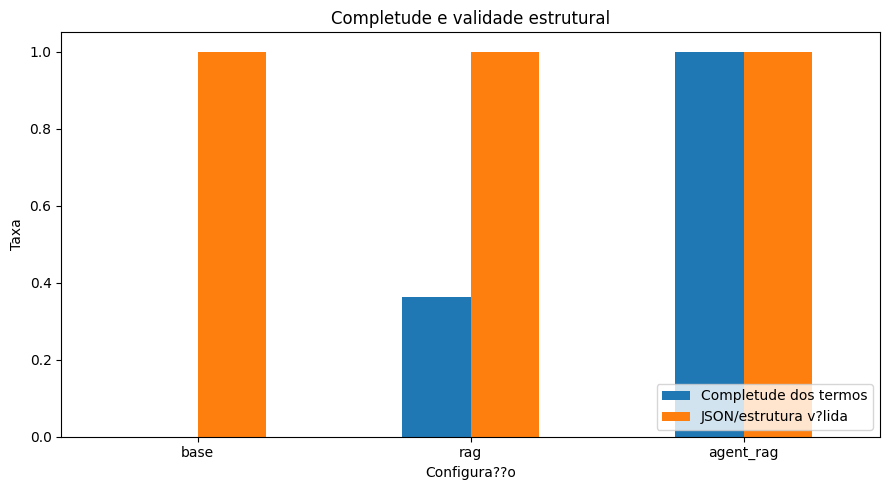

In [5]:
plot_data = comparison.set_index("Configura??o")[
    ["Completude dos termos", "JSON/estrutura v?lida"]
]
ax = plot_data.plot(kind="bar", ylim=(0, 1.05), figsize=(9, 5))
ax.set_ylabel("Taxa")
ax.set_title("Completude e validade estrutural")
ax.legend(loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 4. Interpreta??o

- A recupera??o obteve Recall@1 = 1,0 e Recall@3 = 1,0 nos 11 casos eleg?veis.
- O RAG tradicional teve completude dos termos esperados de 36,36%.
- Agent + RAG teve completude de 100% neste conjunto espec?fico.
- A lat?ncia m?dia de Agent + RAG foi influenciada por respostas determin?sticas, portanto n?o deve ser interpretada como velocidade pura de gera??o do LLM.
- A configura??o Base apresentou dois erros de execu??o por indisponibilidade do Ollama; esses casos n?o s?o erros de conte?do.
- Recall alto n?o garante resposta correta: foram observadas contradi??es na gera??o RAG nos casos QA009 e QA011.


## 5. Limita??es metodol?gicas

1. O conjunto possui apenas 12 perguntas; QA010 n?o possui fonte esperada e ? exclu?do do Recall.
2. A validade de refer?ncia n?o comprova que o conte?do da cita??o sustenta semanticamente a resposta.
3. A valida??o estrutural n?o equivale a uma avalia??o humana completa da qualidade do JSON.
4. Agent + RAG utiliza regras determin?sticas e instru??es; n?o houve fine-tuning LoRA.
5. VRAM e RAM n?o foram medidas nesta execu??o.
6. As corre??es propostas em `avaliacao/erros_reais.md` ainda precisam ser validadas em nova avalia??o.

## 6. Conclus?o

Neste experimento, Agent + RAG apresentou maior completude dos termos esperados, enquanto o RAG tradicional demonstrou recupera??o de fontes adequada, mas limita??es na gera??o. Os resultados s?o v?lidos para o conjunto de teste utilizado e n?o devem ser generalizados sem avalia??es adicionais.
